# India OTT market: why the numbers disagree, and what streaming really costs

This notebook answers three questions using data compiled from official plan pages, industry reports and company statements:

1. **Why do India's OTT subscriber numbers disagree?**
2. **What does OTT really cost in ₹?** (per screen, monthly vs yearly, ad-free 4K)
3. **Are telecom bundles cheaper than buying platforms separately?**

**Data:** every row in `data/*.csv` carries its source URL and the date it was checked. Prices were checked on **23 Nov 2026**.
Values that could not be verified are left blank (unknown), never guessed - see `data/TODO_verify.md`.

All calculations run the named queries in `sql/analysis.sql`, the same ones the dashboard uses and the unit tests check.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "scripts"))

from build_db import build
from run_analysis import load_queries

DB = build(ROOT / "data", ROOT / "build" / "ott.db")   # validates the CSVs first, then rebuilds the database
QUERIES = load_queries()

import sqlite3
from contextlib import closing


def q(name: str) -> pd.DataFrame:
    """Run one named query from sql/analysis.sql."""
    with closing(sqlite3.connect(DB)) as conn:
        return pd.read_sql_query(QUERIES[name], conn)


def table(sql: str) -> pd.DataFrame:
    with closing(sqlite3.connect(DB)) as conn:
        return pd.read_sql_query(sql, conn)


PLATFORM_NAMES = dict(table("SELECT platform_id, name FROM platforms").values) | {"market_total": "All of India"}

# Chart style: one recessive grid, muted axes, thin marks. Colors are the validated reference palette.
SURFACE, TEXT, TEXT_2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": TEXT_2, "xtick.color": TEXT_2, "ytick.color": TEXT,
    "axes.grid": True, "axes.grid.axis": "x", "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "figure.dpi": 110,
})


def source_note(ax, text: str) -> None:
    ax.annotate(text, xy=(0, 0), xycoords="figure fraction", xytext=(8, 6), textcoords="offset points",
                fontsize=8, color=TEXT_2)


print("Database built:", DB.relative_to(ROOT))

Database built: build\ott.db


## 1. What's in the data

Before analysing anything: how many rows, and how much is still unknown? Unknown values are stored as empty (NULL), so they can never be mistaken for zero.

In [2]:
counts = table("""
    SELECT 'platforms' AS dataset, COUNT(*) AS rows FROM platforms UNION ALL
    SELECT 'prices', COUNT(*) FROM prices UNION ALL
    SELECT 'subscribers', COUNT(*) FROM subscribers UNION ALL
    SELECT 'bundles', COUNT(*) FROM bundles
""")
unknown = table("""
    SELECT 'max_screens' AS price_column, SUM(max_screens IS NULL) AS unknown_rows, COUNT(*) AS total FROM prices UNION ALL
    SELECT 'max_quality', SUM(max_quality IS NULL), COUNT(*) FROM prices UNION ALL
    SELECT 'has_ads', SUM(has_ads IS NULL), COUNT(*) FROM prices UNION ALL
    SELECT 'devices', SUM(devices IS NULL), COUNT(*) FROM prices
""")
display(counts, unknown)

,dataset,rows
0,platforms,9
1,prices,48
2,subscribers,19
3,bundles,21


,price_column,unknown_rows,total
0,max_screens,36,48
1,max_quality,3,48
2,has_ads,3,48
3,devices,32,48


Most unknown screen counts come from pages that say "N devices" without saying whether they can stream **at the same time**. Those plans are left out of the per-screen comparison instead of being guessed.

## 2. Why do subscriber numbers disagree?

### The market: one market, four very different numbers

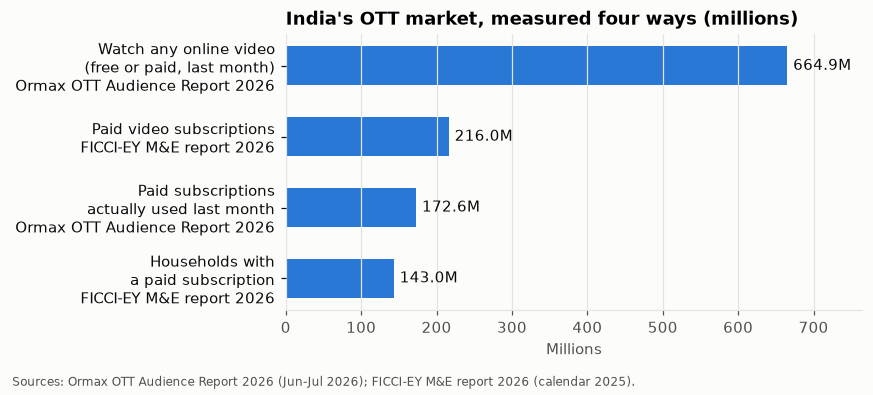

In [3]:
subs = table("SELECT * FROM subscribers")
market = subs[(subs.platform_id == "market_total") & (subs.as_of_date >= "2025-12-31")].copy()
labels = {
    "audience": "Watch any online video\n(free or paid, last month)",
    "subscriptions": "Paid video subscriptions",
    "active_paid_subscriptions": "Paid subscriptions\nactually used last month",
    "subscribing_households": "Households with\na paid subscription",
}
market["label"] = market.metric_type.map(labels) + "\n" + market.source_name.str.replace(r" \(.*\)", "", regex=True)
market = market.sort_values("value")

fig, ax = plt.subplots(figsize=(8, 3.6))
bars = ax.barh(market.label, market.value, color=BLUE, height=0.55)
ax.bar_label(bars, labels=[f"{v:,.1f}M" for v in market.value], padding=4, color=TEXT)
ax.set_title("India's OTT market, measured four ways (millions)")
ax.set_xlabel("Millions")
ax.set_xlim(0, market.value.max() * 1.15)
source_note(ax, "Sources: Ormax OTT Audience Report 2026 (Jun-Jul 2026); FICCI-EY M&E report 2026 (calendar 2025).")
fig.tight_layout(rect=(0, 0.04, 1, 1))
plt.show()

These are **not** competing estimates of the same thing. Each counts something different:

- **664.9M** people watched any online video in the last month, including free YouTube-style viewing (Ormax).
- **216M** paid subscriptions, but they sit in only **143M** households, because one home often pays for several apps (FICCI-EY).
- **172.6M** subscriptions were actually *used* in the last month (Ormax). That's fewer than the 216M paid for, partly because many come free inside telecom plans and go unused.

### JioHotstar: the same platform, 180M to 500M

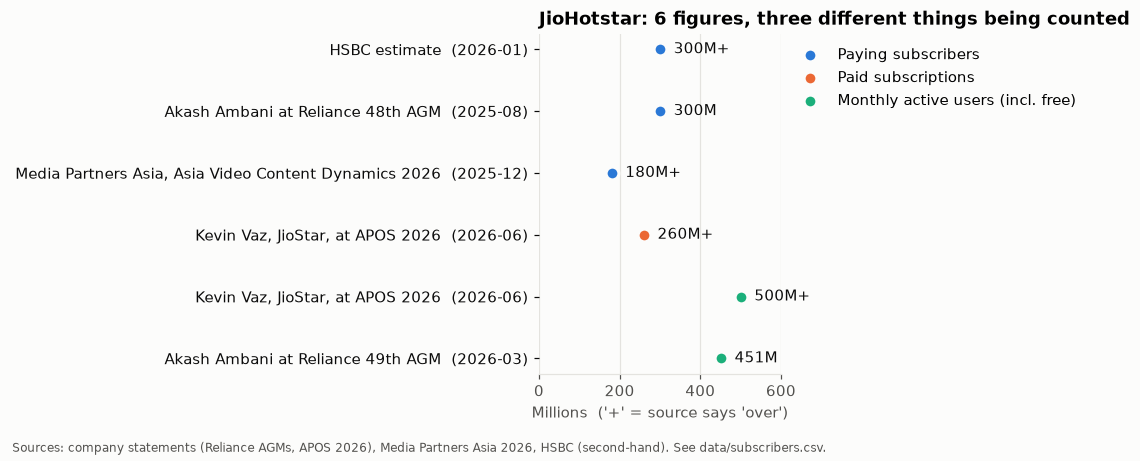

In [4]:
jh = subs[(subs.platform_id == "jiohotstar") & (subs.unit == "millions")].copy()
jh["figure"] = jh.value.fillna(jh.value_low)
jh["at_least"] = jh.value.isna() & jh.value_low.notna()
jh["label"] = jh.source_name.str.replace(r" \(via .*\)", "", regex=True) + "  (" + jh.as_of_date.str[:7] + ")"
metric_style = {
    "paying_subscribers": ("Paying subscribers", BLUE),
    "subscriptions": ("Paid subscriptions", ORANGE),
    "viewers": ("Monthly active users (incl. free)", AQUA),
}
jh["order"] = jh.metric_type.map(list(metric_style).index)
jh = jh.sort_values(["order", "figure"], ascending=[False, True]).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(10, 4.2))
for metric, (name, color) in metric_style.items():
    part = jh[jh.metric_type == metric]
    ax.scatter(part.figure, part.index, s=70, color=color, edgecolor=SURFACE, linewidth=2, label=name, zorder=3)
for i, row in jh.iterrows():
    text = f"{row.figure:,.0f}M" + ("+" if row.at_least else "")
    ax.annotate(text, (row.figure, i), xytext=(9, 0), textcoords="offset points", va="center", color=TEXT)
ax.set_yticks(jh.index, jh.label)
ax.set_xlim(0, 600)
ax.set_xlabel("Millions  ('+' = source says 'over')")
ax.set_title(f"JioHotstar: {len(jh)} figures, three different things being counted")
ax.legend(loc="upper left", bbox_to_anchor=(1.0, 1.0), frameon=False)
source_note(ax, "Sources: company statements (Reliance AGMs, APOS 2026), Media Partners Asia 2026, HSBC (second-hand). See data/subscribers.csv.")
fig.tight_layout(rect=(0, 0.04, 1, 1))
plt.show()

In [5]:
spread = q("subscriber_estimate_spread")
spread["platform"] = spread.platform_id.map(PLATFORM_NAMES)
spread[spread.estimates > 1][["platform", "metric_type", "estimates", "min_estimate", "max_estimate", "spread_pct", "source_types"]]

,platform,metric_type,estimates,min_estimate,max_estimate,spread_pct,source_types
1,JioHotstar,paying_subscribers,3,180.0,300.0,66.7,"company_official,industry_report,broker_note"
3,JioHotstar,viewers,2,451.0,500.0,10.9,company_official
4,All of India,active_paid_subscriptions,2,148.2,172.6,16.5,industry_report
5,All of India,audience,2,601.2,664.9,10.6,industry_report
9,Netflix,paying_subscribers,2,16.0,20.0,25.0,"broker_note,news_report"


**Why they disagree:**

1. **Different things are counted.** "Users" includes free viewers; "subscriptions" can exceed "subscribers" when one person holds several; viewing share (58% for JioHotstar, per Media Partners Asia) isn't a head-count at all.
2. **Different dates.** JioHotstar's 300M peaked during IPL 2025. A year later the company itself said "over 260 million paid *subscriptions*".
3. **Different sources have different incentives.** Companies quote their biggest number; research firms survey usage; broker estimates are often relayed second-hand without a date.

Even when the *same metric* is compared, JioHotstar's paying-subscriber estimates range from **180M to 300M**, a 67% spread.

## 3. What does OTT really cost?

To compare fairly, every price is converted to **₹ per month** (a ₹1,499/year plan = ₹124.92/month), then divided by the number of screens that can stream at the same time.

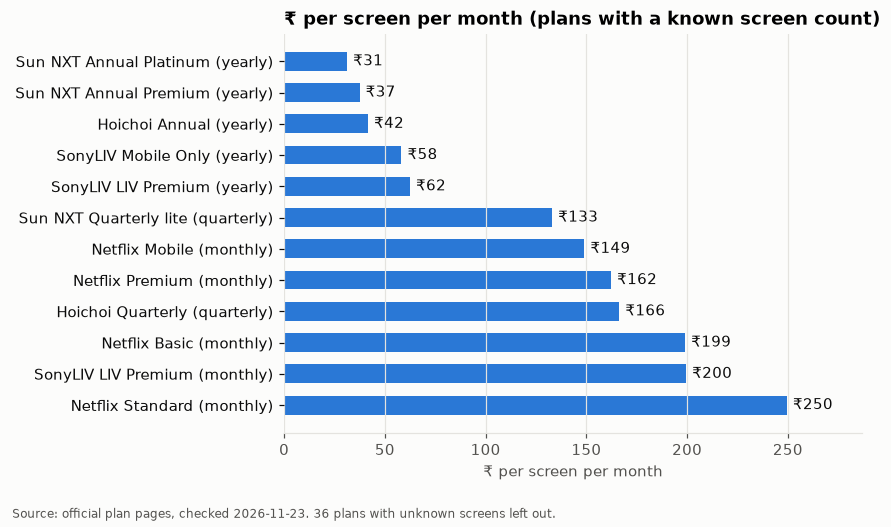

In [6]:
pps = q("price_per_screen")
known = pps[pps.price_per_screen_per_month.notna()].copy()
known["label"] = known.platform_id.map(PLATFORM_NAMES) + " " + known.plan_name + " (" + known.billing_period + "ly)"
known = known.sort_values("price_per_screen_per_month", ascending=False)

fig, ax = plt.subplots(figsize=(8, 4.8))
bars = ax.barh(known.label, known.price_per_screen_per_month, color=BLUE, height=0.6)
ax.bar_label(bars, labels=[f"₹{v:,.0f}" for v in known.price_per_screen_per_month], padding=4, color=TEXT)
ax.set_title("₹ per screen per month (plans with a known screen count)")
ax.set_xlabel("₹ per screen per month")
ax.set_xlim(0, known.price_per_screen_per_month.max() * 1.15)
source_note(ax, f"Source: official plan pages, checked {pps.as_of_date.max()}. {len(pps) - len(known)} plans with unknown screens left out.")
fig.tight_layout(rect=(0, 0.04, 1, 1))
plt.show()

Yearly plans with several screens are by far the cheapest per viewer. Netflix's monthly-only billing makes it the most expensive per screen at every tier.

### The cheapest way into each platform

In [7]:
cheapest = q("cheapest_plan_per_platform")
cheapest["platform"] = cheapest.platform_id.map(PLATFORM_NAMES)
cheapest["devices"] = cheapest.devices.fillna("unknown")
# ZEE5's six regional-language plans tie at the same price; show them as one row.
cheapest = (cheapest.groupby(["platform", "price_per_month", "billing_period", "devices"], as_index=False)
            .agg(plans=("plan_name", lambda s: s.iloc[0] if len(s) == 1 else f"{len(s)} regional-language plans")))
cheapest.sort_values("price_per_month")[["platform", "plans", "billing_period", "price_per_month", "devices"]]

,platform,plans,billing_period,price_per_month,devices
0,Aha,Quarterly Mobile,quarter,33.00,mobile_only
6,ZEE5,6 regional-language plans,year,49.92,unknown
4,SonyLIV,Mobile Only,year,58.25,mobile_only
1,Amazon Prime Video,Prime Lite,year,66.58,all
5,Sun NXT,Annual Premium,year,74.92,unknown
2,Hoichoi,Annual,year,83.25,all
3,Netflix,Mobile,month,149.00,mobile_only


The cheapest entry plans are mostly **mobile-only** or **single-language**. The "starting price" a platform advertises is rarely the plan a family would actually use.

### Paying yearly vs monthly

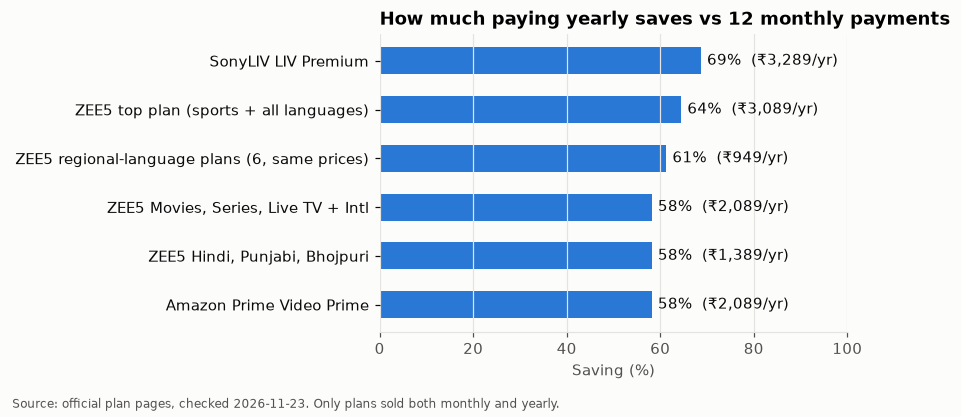

In [8]:
savings = q("annual_vs_monthly_savings")
savings["platform"] = savings.platform_id.map(PLATFORM_NAMES)
regional = savings.plan_name.str.contains("Movies, Series, TV Shows")
savings.loc[regional, "plan_name"] = "regional-language plans (6, same prices)"
savings = savings.drop_duplicates(["platform", "plan_name"])
short_names = {
    "Sports + International Content + KidZ + All Language Content": "top plan (sports + all languages)",
    "Movies, Series, Live TV + KidZ + International Content": "Movies, Series, Live TV + Intl",
    "All content in Hindi, Punjabi, Bhojpuri": "Hindi, Punjabi, Bhojpuri",
}
savings["label"] = savings.platform + " " + savings.plan_name.replace(short_names)
savings = savings.sort_values("savings_pct")

fig, ax = plt.subplots(figsize=(8, 3.8))
bars = ax.barh(savings.label, savings.savings_pct, color=BLUE, height=0.55)
ax.bar_label(bars, labels=[f"{p:.0f}%  (₹{s:,.0f}/yr)" for p, s in zip(savings.savings_pct, savings.yearly_savings_inr)],
             padding=4, color=TEXT)
ax.set_title("How much paying yearly saves vs 12 monthly payments")
ax.set_xlabel("Saving (%)")
ax.set_xlim(0, 100)
source_note(ax, "Source: official plan pages, checked 2026-11-23. Only plans sold both monthly and yearly.")
fig.tight_layout(rect=(0, 0.04, 1, 1))
plt.show()

### Cheapest ad-free 4K

Plans whose ads or quality are unknown are excluded, not assumed.

In [9]:
four_k = q("cheapest_ad_free_4k")
four_k["platform"] = four_k.platform_id.map(PLATFORM_NAMES)
four_k[["platform", "plan_name", "billing_period", "price_inr", "price_per_month", "max_screens"]]

,platform,plan_name,billing_period,price_inr,price_per_month,max_screens
0,Aha,aha GOLD,year,999.0,83.25,NaN
1,Sun NXT,Annual Platinum,year,1499.0,124.92,4.0
2,Netflix,Premium,month,649.0,649.00,4.0


## 4. Are telecom bundles cheaper?

`bundle_vs_separate` compares each bundle's monthly cost with buying the cheapest plan of each included platform separately.
28- and 84-day plans are converted with 365/12 days per month (you recharge 13 times a year, not 12).

**Two cautions before reading the result:**
- **Full prepaid plans also pay for calls and data**, which you'd buy anyway, so comparing their full price with OTT alone is unfair. Only **data-only packs** give a like-for-like comparison. We don't subtract a "base plan" price because we haven't collected one; that would be a guess.
- Most bundles include **JioHotstar**, which has no verified price yet, so those comparisons are incomplete and left out below.

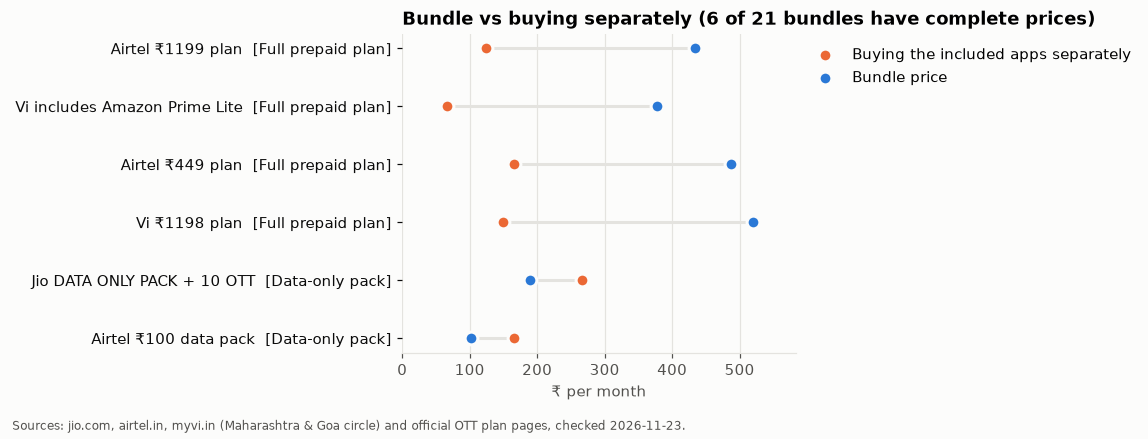

,label,plan_type,bundle_per_month,separate_per_month,monthly_savings
0,Airtel ₹100 data pack,Data-only pack,101.39,166.17,64.78
1,Jio DATA ONLY PACK + 10 OTT,Data-only pack,190.10,266.33,76.23
2,Vi ₹1198 plan,Full prepaid plan,520.56,149.00,-371.56
3,Airtel ₹449 plan,Full prepaid plan,487.75,166.17,-321.59
4,Vi includes Amazon Prime Lite,Full prepaid plan,378.04,66.58,-311.45
5,Airtel ₹1199 plan,Full prepaid plan,434.16,124.83,-309.33


In [10]:
bundles = q("bundle_vs_separate")
notes = table("SELECT provider, bundle_name, notes FROM bundles")
bundles = bundles.merge(notes, on=["provider", "bundle_name"])
bundles["plan_type"] = bundles.notes.str.startswith("Data pack only").map({True: "Data-only pack", False: "Full prepaid plan"})
complete = bundles[bundles.complete_comparison == 1].copy()
complete["label"] = complete.provider + " " + complete.bundle_name.str.replace(" (no name shown)", "", regex=False)
complete = complete.sort_values(["plan_type", "monthly_savings"]).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(10.5, 4))
for i, row in complete.iterrows():
    ax.plot([row.separate_per_month, row.bundle_per_month], [i, i], color=GRID, linewidth=2, zorder=1)
ax.scatter(complete.separate_per_month, complete.index, s=70, color=ORANGE, edgecolor=SURFACE, linewidth=2,
           label="Buying the included apps separately", zorder=3)
ax.scatter(complete.bundle_per_month, complete.index, s=70, color=BLUE, edgecolor=SURFACE, linewidth=2,
           label="Bundle price", zorder=3)
ax.set_yticks(complete.index, complete.label + "  [" + complete.plan_type + "]")
ax.set_xlim(0, complete[["bundle_per_month", "separate_per_month"]].max().max() * 1.12)
ax.set_xlabel("₹ per month")
ax.set_title(f"Bundle vs buying separately ({len(complete)} of {len(bundles)} bundles have complete prices)")
ax.legend(loc="upper left", bbox_to_anchor=(1.0, 1.0), frameon=False)
source_note(ax, "Sources: jio.com, airtel.in, myvi.in (Maharashtra & Goa circle) and official OTT plan pages, checked 2026-11-23.")
fig.tight_layout(rect=(0, 0.04, 1, 1))
plt.show()

complete[["label", "plan_type", "bundle_per_month", "separate_per_month", "monthly_savings"]]

For **data-only packs**, the fair comparison, bundles can be genuinely cheaper than paying for the same apps directly. Full prepaid plans look expensive here only because their price also covers calls and data.

Note the catch: bundled apps are usually the **mobile** tier (JioHotstar Mobile, Prime Video Mobile Edition), or arrive through an aggregator app instead of the platform's own.

## 5. Key insights

1. **"How many Indians pay for OTT?" has no single answer, because each source counts something different.** In 2025–26, 664.9M people watched online video, 216M paid subscriptions were held by 143M households, but only 172.6M subscriptions were actually used in a month. Always ask *what* a number counts before comparing it.
2. **Even on the same measure, the largest platform's numbers swing widely.** JioHotstar's paying-subscriber estimates range from 180M to 300M (a 67% spread). The company itself went from "300 million paying subscribers" (Aug 2025, during the IPL boom) to "over 260 million paid subscriptions" (Jun 2026).
3. **Paying yearly saves 58–69%** on every plan sold both ways. SonyLIV Premium costs ₹4,788 over 12 monthly payments but ₹1,499 for a year.
4. **Per screen, multi-screen yearly plans are 2–8× cheaper than Netflix.** Sun NXT, Hoichoi and SonyLIV yearly plans cost ₹31–62 per screen per month; Netflix (monthly billing only) costs ₹149–250. The cheapest ad-free 4K option is Aha GOLD at ₹83/month vs Netflix Premium at ₹649/month.
5. **Telecom data packs can beat buying apps directly, but with a catch.** Airtel's ₹100 and Jio's ₹175 data packs cost ₹65–76/month less than buying the same apps separately. However, bundled apps are usually mobile-only tiers or come through an aggregator app, and 15 of 21 bundles can't yet be compared because JioHotstar's own prices are still unverified.

## Limitations
- Prices were checked on one day (23 Nov 2026) and change often; telecom prices are for one circle (Maharashtra & Goa).
- Some rows were collected through Claude chat browsing and are not yet hand-checked (each row's `notes` says so).
- JioHotstar and Planet Marathi prices, and Tata Play Binge plans, are missing (`data/TODO_verify.md`).
- Several subscriber figures come from second-hand reports (HSBC via an entertainment site; Netflix via a podcast).